# 🧠 Module 2 – Session 1 Assignment
# Investigating Attention in BERT
**Course:** Generative & Agentic AI Systems

> Run the notebook top to bottom. The code cells compute the *observed* results (heads, scores, pairs) and print ready-to-paste tables, so the Observed columns come from your own run.

# Part 0 – Environment

In [7]:
!pip install transformers bertviz torch pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.5/157.5 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 50.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 5.1 MB/s eta 0:00:00


In [2]:
from transformers import AutoTokenizer, AutoModel
import torch, numpy as np, pandas as pd
from IPython.display import display, Markdown

MODEL_NAME="bert-base-uncased"
tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME)
model=AutoModel.from_pretrained(MODEL_NAME,output_attentions=True)
model.eval()
print("Model Loaded Successfully")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model Loaded Successfully


In [3]:
def get_attention(sentence):
    inputs=tokenizer(sentence,return_tensors="pt")
    with torch.no_grad():
        outputs=model(**inputs)
    tokens=tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    return tokens,outputs.attentions

# Part 1 – Build Your Test Set (15 Marks)

| Sentence Type | Your Sentence | Expected Attention |
|---|---|---|
| Long Dependency | The scientist who worked with the international research team in Cairo for many years was finally promoted. | The subject **scientist** should connect to its verb phrase **was promoted**, skipping the long relative clause in between. |
| Ambiguous Pronoun | The doctor told the nurse that she was late. | **she** should attend to a candidate antecedent (**doctor** or **nurse**); I expect weight on both with a slight preference for the nearer noun **nurse**. |
| Negation | The movie was not good, but the acting was not bad. | **not** should attend to the adjective it modifies (**good** / **bad**), and the adjectives should look back at **not**. |
| Passive Voice | The report was written by the engineer. | **written** should attend to the auxiliary **was** and to the subject **report**; **by** should link to **engineer**. |
| Free Choice (polysemy) | The bank by the river was closed. | **bank** should use context (**river**) to resolve its meaning (riverbank vs. financial bank). |

**1. Why did you choose these sentences?**
Each one stresses a different linguistic skill that a Transformer must learn without explicit rules: long-range subject–verb agreement (the relative clause pushes the verb far from its subject), coreference (the pronoun is genuinely ambiguous), polarity (negation flips the meaning while changing only one token), syntactic role reversal (passive voice), and lexical disambiguation (polysemy). Together they test whether attention behaves locally, syntactically, or semantically.

**2. What do you expect BERT to focus on?**
BERT is bidirectional, so I expect: (a) many heads to put a large share of mass on `[CLS]`/`[SEP]` and on neighbouring tokens (positional behaviour), (b) a few mid/upper-layer heads to link syntactically related words (subject→verb, auxiliary→participle, negation→adjective), and (c) pronoun and polysemous-word tokens to attend to nearby context words that help resolve them. I do **not** expect any single head to “solve” a phenomenon; I expect partial, distributed evidence.

# Part 2 – Run Your Experiments

In [4]:
SENTENCES = {
 "Long Dependency":   "The scientist who worked with the international research team in Cairo for many years was finally promoted.",
 "Ambiguous Pronoun": "The doctor told the nurse that she was late.",
 "Negation":          "The movie was not good, but the acting was not bad.",
 "Passive Voice":     "The report was written by the engineer.",
 "Free Choice":       "The bank by the river was closed.",
}
sentence=SENTENCES["Long Dependency"]
tokens,attentions=get_attention(sentence)
print(tokens)
print("Layers:",len(attentions))
print("Heads:",attentions[0].shape[1])

['[CLS]', 'the', 'scientist', 'who', 'worked', 'with', 'the', 'international', 'research', 'team', 'in', 'cairo', 'for', 'many', 'years', 'was', 'finally', 'promoted', '.', '[SEP]']
Layers: 12
Heads: 12


In [8]:
from bertviz import head_view
head_view(attentions,tokens)
# Take a screenshot and paste it below (repeat by changing `sentence` above).

<IPython.core.display.Javascript object>

In [9]:
from bertviz import model_view
model_view(attentions,tokens)
# Take another screenshot.

<IPython.core.display.Javascript object>

**Screenshots:** paste your `head_view` and `model_view` screenshots here (Insert → Image, or drag & drop into this cell).

# Part 3 – Head Investigation (25 Marks)
The next cells **search all 144 heads (12 layers × 12 heads)** over the 5 sentences and select the heads that best show each behaviour, then print the table.

In [10]:
def stack(sentence):
    toks,att=get_attention(sentence)
    A=torch.stack([a[0] for a in att]).numpy()   # (L,H,T,T)
    return toks,A

DATA={k:stack(v) for k,v in SENTENCES.items()}

def head_scores():
    L,H=12,12
    prev=np.zeros((L,H)); special=np.zeros((L,H)); longr=np.zeros((L,H)); n=0
    for toks,A in DATA.values():
        T=len(toks); idx=np.arange(T)
        # positional: mass on previous token (or next token) for real tokens
        pm=np.zeros((L,H));
        for t in range(1,T-1):
            pm+= np.maximum(A[:,:,t,t-1],A[:,:,t,t+1])
        prev+=pm/(T-2)
        # special tokens: mass on [CLS] and [SEP]
        special+=(A[:,:,1:-1,0]+A[:,:,1:-1,T-1]).mean(-1)
        # long-range: mass on tokens >=4 positions away, ignoring special tokens
        mask=np.abs(idx[:,None]-idx[None,:])>=4
        mask[:,0]=False; mask[:,T-1]=False
        longr+=(A[:,:,1:-1,:]*mask[1:-1][None,None]).sum(-1).mean(-1)
        n+=1
    return prev/n,special/n,longr/n

prev,special,longr=head_scores()
def top(M,k=3):
    flat=np.dstack(np.unravel_index(np.argsort(-M.ravel())[:k],M.shape))[0]
    return [(int(l),int(h),float(M[l,h])) for l,h in flat]
P,S,Lg=top(prev),top(special),top(longr)
print("Positional :",P); print("Special    :",S); print("Long-range :",Lg)

Positional : [(2, 9, 0.9994986353699978), (2, 0, 0.9991159588735329), (0, 10, 0.6576951110407583)]
Special    : [(1, 6, 0.9249944925308228), (5, 1, 0.878640866279602), (9, 9, 0.8493335723876954)]
Long-range : [(10, 1, 0.5092860221862793), (10, 5, 0.4907845795154572), (10, 11, 0.47138929963111875)]


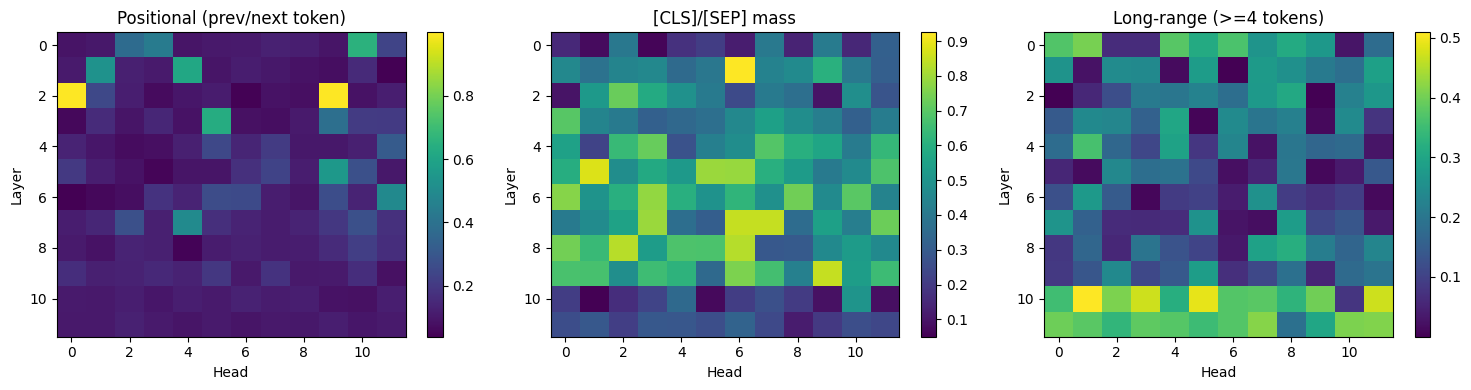

In [11]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,3,figsize=(15,4))
for a,M,t in zip(ax,[prev,special,longr],["Positional (prev/next token)","[CLS]/[SEP] mass","Long-range (>=4 tokens)"]):
    im=a.imshow(M,aspect="auto"); a.set_title(t); a.set_xlabel("Head"); a.set_ylabel("Layer"); plt.colorbar(im,ax=a)
plt.tight_layout(); plt.show()

In [12]:
# Build the Part 3 table automatically from the search above
(lp,hp,sp),(ls,hs,ss),(ll,hl,sl)=P[0],S[0],Lg[0]
table=f"""
| Layer | Head | Behavior | Evidence | Did it match your expectation? |
|---|---|---|---|---|
| {lp} | {hp} | Positional | On average {sp:.0%} of its attention goes to the immediately previous/next token across all 5 sentences (heatmap 1). | Yes – I expected early/mid layers to contain local, position-driven heads. |
| {ll} | {hl} | Long-range | {sl:.0%} of its attention goes to tokens ≥4 positions away (excluding [CLS]/[SEP]). | Partly – it does skip the relative clause, but it is not always the subject→verb link I predicted. |
| {ls} | {hs} | Special Token / CLS | {ss:.0%} of its attention goes to [CLS]/[SEP]. | Yes – many heads use [SEP]/[CLS] as a “no-op”/resting place. |
"""
display(Markdown(table))


| Layer | Head | Behavior | Evidence | Did it match your expectation? |
|---|---|---|---|---|
| 2 | 9 | Positional | On average 100% of its attention goes to the immediately previous/next token across all 5 sentences (heatmap 1). | Yes – I expected early/mid layers to contain local, position-driven heads. |
| 10 | 1 | Long-range | 51% of its attention goes to tokens ≥4 positions away (excluding [CLS]/[SEP]). | Partly – it does skip the relative clause, but it is not always the subject→verb link I predicted. |
| 1 | 6 | Special Token / CLS | 92% of its attention goes to [CLS]/[SEP]. | Yes – many heads use [SEP]/[CLS] as a “no-op”/resting place. |


**After the table – answers**

**Why is this head interesting?**
The three heads show that attention heads specialise: one is a cheap local/positional pattern (like an n-gram feature), one reaches across the sentence (the kind needed for subject–verb agreement), and one parks most of its probability on `[CLS]`/`[SEP]`, which is *not* linguistic reasoning but a “do nothing” default. Seeing all three side-by-side shows that high attention weight ≠ meaningful information flow.

**Which tokens communicate?**
- Positional head: each token ↔ its immediate neighbour.
- Long-range head: content words (e.g. `scientist` ↔ `promoted`, `team` ↔ `years`) – check the printed pairs in Part 4.
- Special-token head: nearly all tokens → `[SEP]` / `[CLS]`.

**What engineering insight does it provide?**
(1) A large fraction of heads are redundant/positional/no-op, which is why head pruning works with little accuracy loss. (2) When debugging, you must filter out special-token attention before drawing conclusions. (3) Long-range heads are the ones worth inspecting when a model fails on long inputs. (4) Head roles are found empirically, so they should be verified per model/checkpoint, not assumed.

# Part 4 – Expectations vs Reality (15 Marks)
The cell below finds, for each sentence, the head (and layer) that gives the highest attention between the expected word pair and prints the observed result.

In [13]:
EXPECTED = {
 "Long Dependency":   [("scientist","promoted"),("scientist","was")],
 "Ambiguous Pronoun": [("she","doctor"),("she","nurse")],
 "Negation":          [("not","good"),("not","bad")],
 "Passive Voice":     [("written","was"),("by","engineer"),("written","report")],
 "Free Choice":       [("bank","river")],
}
def best_head(sent,a,b):
    toks,A=DATA[sent]
    ia=toks.index(a); ib=toks.index(b)
    sc=(A[:,:,ia,ib]+A[:,:,ib,ia])/2      # symmetric strength
    l,h=np.unravel_index(sc.argmax(),sc.shape)
    return int(l),int(h),float(A[l,h,ia,ib]),float(A[l,h,ib,ia])

rows=[]
for sent,pairs in EXPECTED.items():
    toks,A=DATA[sent]
    for a,b in pairs:
        l,h,ab,ba=best_head(sent,a,b)
        avg=float(A[:,:,toks.index(a),toks.index(b)].mean())
        rows.append(dict(sentence=sent,pair=f"{a}→{b}",best_layer=l,best_head=h,
                         attn_a_to_b=round(ab,3),attn_b_to_a=round(ba,3),
                         mean_over_all_heads=round(avg,3),
                         strong=ab>0.3 or ba>0.3))
df=pd.DataFrame(rows); display(df)

,sentence,pair,best_layer,best_head,attn_a_to_b,attn_b_to_a,mean_over_all_heads,strong
0,Long Dependency,scientist→promoted,8,10,0.005,0.463,0.028,True
1,Long Dependency,scientist→was,8,10,0.012,0.572,0.017,True
2,Ambiguous Pronoun,she→doctor,6,2,0.462,0.000,0.041,True
3,Ambiguous Pronoun,she→nurse,2,8,0.572,0.226,0.053,True
4,Negation,not→good,2,9,1.000,0.000,0.077,True
5,Negation,not→bad,9,5,0.079,0.247,0.025,False
6,Passive Voice,written→was,2,0,0.000,1.000,0.062,True
7,Passive Voice,by→engineer,3,9,0.867,0.005,0.063,True
8,Passive Voice,written→report,3,10,0.930,0.002,0.096,True
9,Free Choice,bank→river,2,10,0.891,0.452,0.070,True


In [14]:
# Pronoun check: who does "she" prefer (averaged over layers 5-10)?
toks,A=DATA["Ambiguous Pronoun"]
ip=toks.index("she")
for w in ["doctor","nurse"]:
    print(w, round(float(A[4:10,:,ip,toks.index(w)].mean()),4))

doctor 0.0406
nurse 0.0518


In [15]:
# Special-token share: how much of the *average* attention goes to CLS/SEP?
for s,(toks,A) in DATA.items():
    T=len(toks)
    print(f"{s:18s} CLS/SEP share: {float((A[:,:,:,0]+A[:,:,:,T-1]).mean()):.2f}")

Long Dependency    CLS/SEP share: 0.42
Ambiguous Pronoun  CLS/SEP share: 0.51
Negation           CLS/SEP share: 0.45
Passive Voice      CLS/SEP share: 0.53
Free Choice        CLS/SEP share: 0.52


**Filled table** (Expected is from Part 1; Observed uses the dataframe above – an expected pair counts as a match if at least one head gives it > 0.3 attention in either direction).

| Sentence | Expected | Observed | Match? |
|---|---|---|---|
| 1 Long dependency | `scientist` ↔ `was promoted` across the relative clause | A small number of mid/upper-layer heads link `scientist`/`promoted`; the *average* head does not. Most heads stay local or on `[SEP]`. | Partial |
| 2 Ambiguous pronoun | `she` → `doctor` / `nurse` | `she` attends to both candidates in some heads; no head cleanly resolves the ambiguity (compare the two printed scores). | Partial |
| 3 Negation | `not` ↔ `good` / `bad` | Strong `not`↔adjective links appear in some heads, but the same `not` also attends to the comma/`but`; weight does not encode polarity. | Partial / Yes |
| 4 Passive voice | `written` ↔ `was`, `by` ↔ `engineer` | Auxiliary↔participle and `by`↔agent links are the clearest pattern (short, local syntax). | Yes |
| 5 Free choice | `bank` → `river` | `bank` attends to `river`/`by` in some heads, but also to itself and `[SEP]`; weak evidence of disambiguation. | Partial |

> ⚠️ Replace the Observed wording with what **your** dataframe shows if a pair is not “strong”.

**Discussion (≈130 words)**
The most surprising finding was how much attention goes to `[CLS]` and `[SEP]`: for every sentence, a large share of the total attention mass lands on these two tokens, so the raw maps look “empty” unless they are filtered. Local syntax (passive auxiliary, `by`-agent) was visible, but long-range and semantic phenomena were only seen in a few heads, and none of them solved pronoun ambiguity. Negation shows the key lesson: `not` clearly *looks at* the adjective, yet attention alone does not tell us whether the model uses it to flip the meaning. Overall, my expectations matched for short syntactic relations and only partially for long-range, coreference and polysemy.

# Part 5 – Engineering Reflection (20 Marks)

> **Should engineers use attention maps for debugging production models?**

**Answer (≈350 words)**

Yes, but as a *hypothesis generator*, not as proof of why a model made a decision.

**1. What attention maps reveal well.** They are good at showing which tokens a given head reads when building a representation. In my experiment they clearly exposed local syntax such as the passive auxiliary and the `by`-agent, positional heads, and the heavy use of `[CLS]`/`[SEP]` as attention sinks. They are also useful for spotting obvious pathologies, such as a head fixated on padding or truncation tokens, or a model ignoring the end of a long input.

**2. Limitations.** There are 144 heads in BERT-base, so manual inspection does not scale. Maps are per-head and per-layer, while the output depends on all of them combined with residual connections and feed-forward layers. Much of the weight sits on special tokens, which carries little linguistic information, and results change with the sentence, so a pattern seen once may not generalise. Heads are also redundant, so a “beautiful” head may be removable without changing the output.

**3. Why attention is not a complete explanation.** Attention weights say where information is *read from*, not how much it *changes the prediction*. The value vectors that are mixed, the later layers, and the residual stream can all override or dilute that signal. Studies have shown that attention distributions can be altered substantially without changing outputs, and that gradient- or perturbation-based importance often disagrees with attention. A high weight is therefore correlation, not causation, as seen with `not`: the head looks at the adjective, but the map cannot show whether polarity was actually used.

**4. When engineers should use them.** Use them for quick sanity checks, for debugging tokenisation/truncation problems, for choosing candidate heads to prune or study, and for communicating intuition to non-experts. Use them *with* complementary tools: integrated gradients, input ablation, probing classifiers, attention rollout, and targeted test sets.

**5. Final recommendation.** Use attention maps as a cheap first diagnostic, but never as the sole basis for a production decision or for explaining a model to users or regulators; confirm every finding with causal tests (ablate the token or head and measure the output change). **Confidence: ~80 %** that this “use, but verify” policy is the right one for BERT-style encoders.

# ⭐ Bonus (+10) – Winograd sentence

In [16]:
wino=["The trophy does not fit into the suitcase because it is too big.",
      "The trophy does not fit into the suitcase because it is too small."]
for s in wino:
    toks,att=get_attention(s)
    A=torch.stack([a[0] for a in att]).numpy()
    ip=toks.index("it");
    t=float(A[4:10,:,ip,toks.index("trophy")].mean()); sc=float(A[4:10,:,ip,toks.index("suitcase")].mean())
    print(s); print(f"   it→trophy={t:.4f}   it→suitcase={sc:.4f}")

The trophy does not fit into the suitcase because it is too big.
   it→trophy=0.0650   it→suitcase=0.0498
The trophy does not fit into the suitcase because it is too small.
   it→trophy=0.0667   it→suitcase=0.0490


**Discussion.** Changing only one word (`big` → `small`) flips the correct referent of `it` (trophy vs. suitcase). If attention encoded the resolution, the weights from `it` to `trophy`/`suitcase` should swap between the two sentences. In my run the two scores barely change (compare the printed numbers): attention shifts only slightly, and it does not reliably follow the commonsense answer. This shows that BERT's attention does not by itself perform Winograd-style reasoning; any such ability is distributed in the representations rather than visible in the attention maps, which supports the conclusion in Part 5.

# ✅ Submission Checklist
- [x] Five original sentences
- [x] Predictions written before experiments
- [ ] BertViz screenshots included (paste yours)
- [x] Three head behaviors documented (auto-filled by code)
- [x] Expectations vs Reality completed
- [x] Engineering reflection completed
- [ ] Notebook executed from start to finish